In [ ]:
# Latent Class Analysis of House Types

## Aim

This analysis groups normal house sales into latent classes based only on their qualitative characteristics (location, building type, quality ratings). We then examine how price relates to living area within each class. This is the first step towards a latent class regression, in which class membership and the price model are estimated jointly.

## Method

Latent class analysis (LCA) assumes each house belongs to one of K hidden classes, and that within a class its qualitative characteristics are independent (local independence). Parameters are estimated by maximum likelihood using the EM algorithm, from multiple random starts. K is chosen by BIC, checked against 5-fold cross-validated log-likelihood.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.special import logsumexp

# ---------------- Settings ----------------
LCA_COLS = ["Neighborhood", "MSZoning", "BldgType", "HouseStyle", "Foundation",
            "ExterQual", "KitchenQual", "BsmtQual", "GarageType", "GarageFinish"]
MIN_LEVEL = 20        # levels with fewer houses are merged into "Other"
K_RANGE = range(1, 9) # numbers of classes to compare (K = 1 is the no-clustering baseline)
N_STARTS = 20         # random starts per fit (EM finds local optima)
ALPHA = 1.0           # smoothing: adds ALPHA pseudo-counts to every level, avoiding zero probabilities
N_FOLDS = 5
SEED = 42

rng = np.random.default_rng(SEED)
train = pd.read_csv("../data/train.csv")
normal = train[train["SaleCondition"] == "Normal"].copy().reset_index(drop=True)

for c in LCA_COLS:
    normal[c] = normal[c].fillna("NA").astype(str)
    counts = normal[c].value_counts()
    rare = counts[counts < MIN_LEVEL].index
    normal[c] = normal[c].where(~normal[c].isin(rare), "Other")

# Integer codes for each column, plus one-hot matrices for fast counting
levels = {c: pd.Categorical(normal[c]).categories for c in LCA_COLS}
X = np.column_stack([pd.Categorical(normal[c], categories=levels[c]).codes for c in LCA_COLS])
n_levels = [len(levels[c]) for c in LCA_COLS]
onehots = [np.eye(C)[X[:, j]] for j, C in enumerate(n_levels)]

n = len(normal)
print(f"{n} normal sales, {len(LCA_COLS)} variables, levels per variable: "
      + ", ".join(f"{c} {C}" for c, C in zip(LCA_COLS, n_levels)))

1198 normal sales, 10 variables, levels per variable: Neighborhood 19, MSZoning 4, BldgType 5, HouseStyle 6, Foundation 5, ExterQual 4, KitchenQual 4, BsmtQual 5, GarageType 5, GarageFinish 4


In [3]:
def log_joint(Xs, pi, theta):
    """log P(class k) + Σ_j log P(x_ij | class k), for every house i and class k. Shape (n, K)."""
    L = np.tile(np.log(pi), (len(Xs), 1))
    for j, th in enumerate(theta):
        L += np.log(th[:, Xs[:, j]]).T
    return L

def fit_lca(Xs, oh, K, n_starts, rng, max_iter=1000, tol=1e-8):
    """Fit an LCA with K classes by EM from several random starts; return the best fit."""
    best = None
    for _ in range(n_starts):
        pi = np.full(K, 1 / K)
        theta = [rng.dirichlet(np.ones(C), size=K) for C in n_levels]
        prev_ll = -np.inf
        for _ in range(max_iter):
            # E-step: responsibilities R[i, k] = P(class k | house i's categories)
            L = log_joint(Xs, pi, theta)
            ll_i = logsumexp(L, axis=1)
            R = np.exp(L - ll_i[:, None])
            ll = ll_i.sum()
            # M-step: class sizes and within-class category probabilities
            Nk = R.sum(axis=0)
            pi = Nk / len(Xs)
            theta = [(R.T @ oh_j + ALPHA) / (Nk[:, None] + ALPHA * oh_j.shape[1]) for oh_j in oh]
            if ll - prev_ll < tol * abs(ll):
                break
            prev_ll = ll
        L = log_joint(Xs, pi, theta)
        ll_i = logsumexp(L, axis=1)
        ll = ll_i.sum()
        if best is None or ll > best["ll"]:
            best = {"ll": ll, "pi": pi, "theta": theta, "R": np.exp(L - ll_i[:, None])}
    return best

def n_params(K):
    return (K - 1) + K * sum(C - 1 for C in n_levels)

In [ ]:
## Choosing the number of classes

For each K we compute BIC (lower is better), which penalises the number of parameters, and the average held-out log-likelihood per house from 5-fold cross-validation (higher is better).

K = 1: BIC = 27,753, CV log-lik/house = -11.4743
K = 2: BIC = 24,300, CV log-lik/house = -9.9182
K = 3: BIC = 23,397, CV log-lik/house = -9.4250
K = 4: BIC = 23,276, CV log-lik/house = -9.2538
K = 5: BIC = 23,257, CV log-lik/house = -9.1586
K = 6: BIC = 23,280, CV log-lik/house = -9.0181
K = 7: BIC = 23,373, CV log-lik/house = -8.9143
K = 8: BIC = 23,477, CV log-lik/house = -8.8529


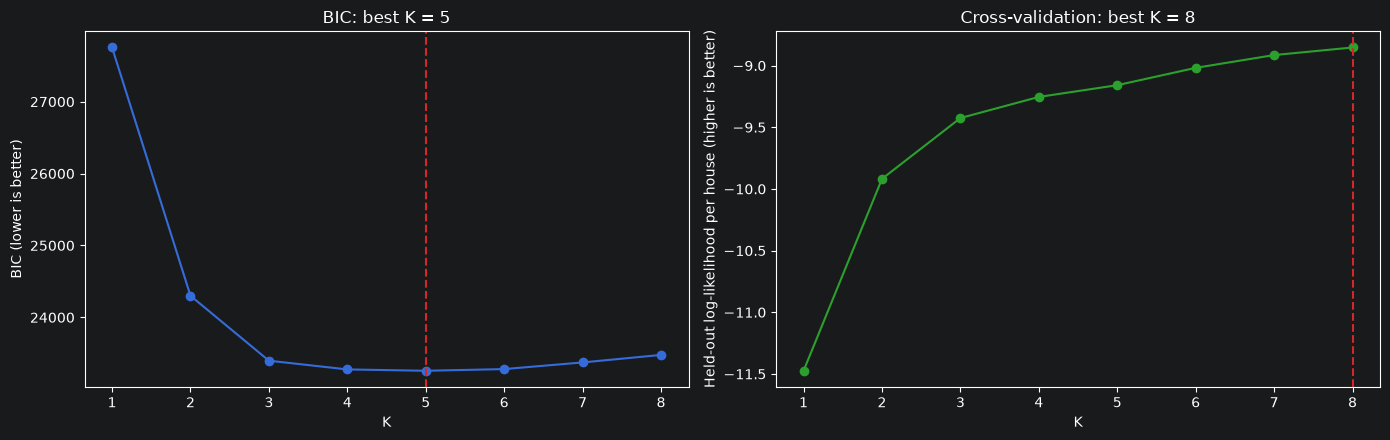

In [4]:
folds = np.array_split(rng.permutation(n), N_FOLDS)
rows = []
for K in K_RANGE:
    fit = fit_lca(X, onehots, K, N_STARTS, rng)
    bic = -2 * fit["ll"] + n_params(K) * np.log(n)

    cv_ll = 0.0
    for test_idx in folds:
        train_idx = np.setdiff1d(np.arange(n), test_idx)
        f = fit_lca(X[train_idx], [oh[train_idx] for oh in onehots], K, N_STARTS // 2, rng)
        cv_ll += logsumexp(log_joint(X[test_idx], f["pi"], f["theta"]), axis=1).sum()

    rows.append({"K": K, "log_lik": fit["ll"], "params": n_params(K), "BIC": bic,
                 "cv_loglik_per_house": cv_ll / n})
    print(f"K = {K}: BIC = {bic:,.0f}, CV log-lik/house = {cv_ll / n:.4f}")

sel = pd.DataFrame(rows)
K_BIC = int(sel.loc[sel["BIC"].idxmin(), "K"])
K_CV = int(sel.loc[sel["cv_loglik_per_house"].idxmax(), "K"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(sel["K"], sel["BIC"], "o-"); axes[0].axvline(K_BIC, color="tab:red", ls="--")
axes[0].set_xlabel("K"); axes[0].set_ylabel("BIC (lower is better)"); axes[0].set_title(f"BIC: best K = {K_BIC}")
axes[1].plot(sel["K"], sel["cv_loglik_per_house"], "o-", color="tab:green")
axes[1].axvline(K_CV, color="tab:red", ls="--")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Held-out log-likelihood per house (higher is better)")
axes[1].set_title(f"Cross-validation: best K = {K_CV}")
plt.tight_layout(); plt.show()

In [5]:
K = K_BIC                     # override here if you prefer K_CV or another value
final = fit_lca(X, onehots, K, N_STARTS * 2, rng)

# Order classes by median price so class numbers mean something (and are stable between runs)
hard = final["R"].argmax(axis=1)
order = np.argsort([normal.loc[hard == k, "SalePrice"].median() for k in range(K)])
remap = np.empty(K, dtype=int); remap[order] = np.arange(K)
final["pi"] = final["pi"][order]
final["theta"] = [th[order] for th in final["theta"]]
final["R"] = final["R"][:, order]
normal["Class"] = remap[hard] + 1
normal["ClassProb"] = final["R"].max(axis=1)

# Entropy-based certainty: 1 = every house clearly in one class, 0 = no separation
R = np.clip(final["R"], 1e-12, 1)
entropy = 1 - (-(R * np.log(R)).sum()) / (n * np.log(K)) if K > 1 else 1.0
print(f"K = {K}, classification certainty (entropy R²) = {entropy:.3f}")
print(f"Share of houses assigned with probability > 0.9: {(normal['ClassProb'] > 0.9).mean():.1%}")
display(normal["Class"].value_counts().sort_index().rename("houses").to_frame())

K = 5, classification certainty (entropy R²) = 0.957
Share of houses assigned with probability > 0.9: 91.5%


,houses
Class,
1,57
2,218
3,65
4,462
5,396


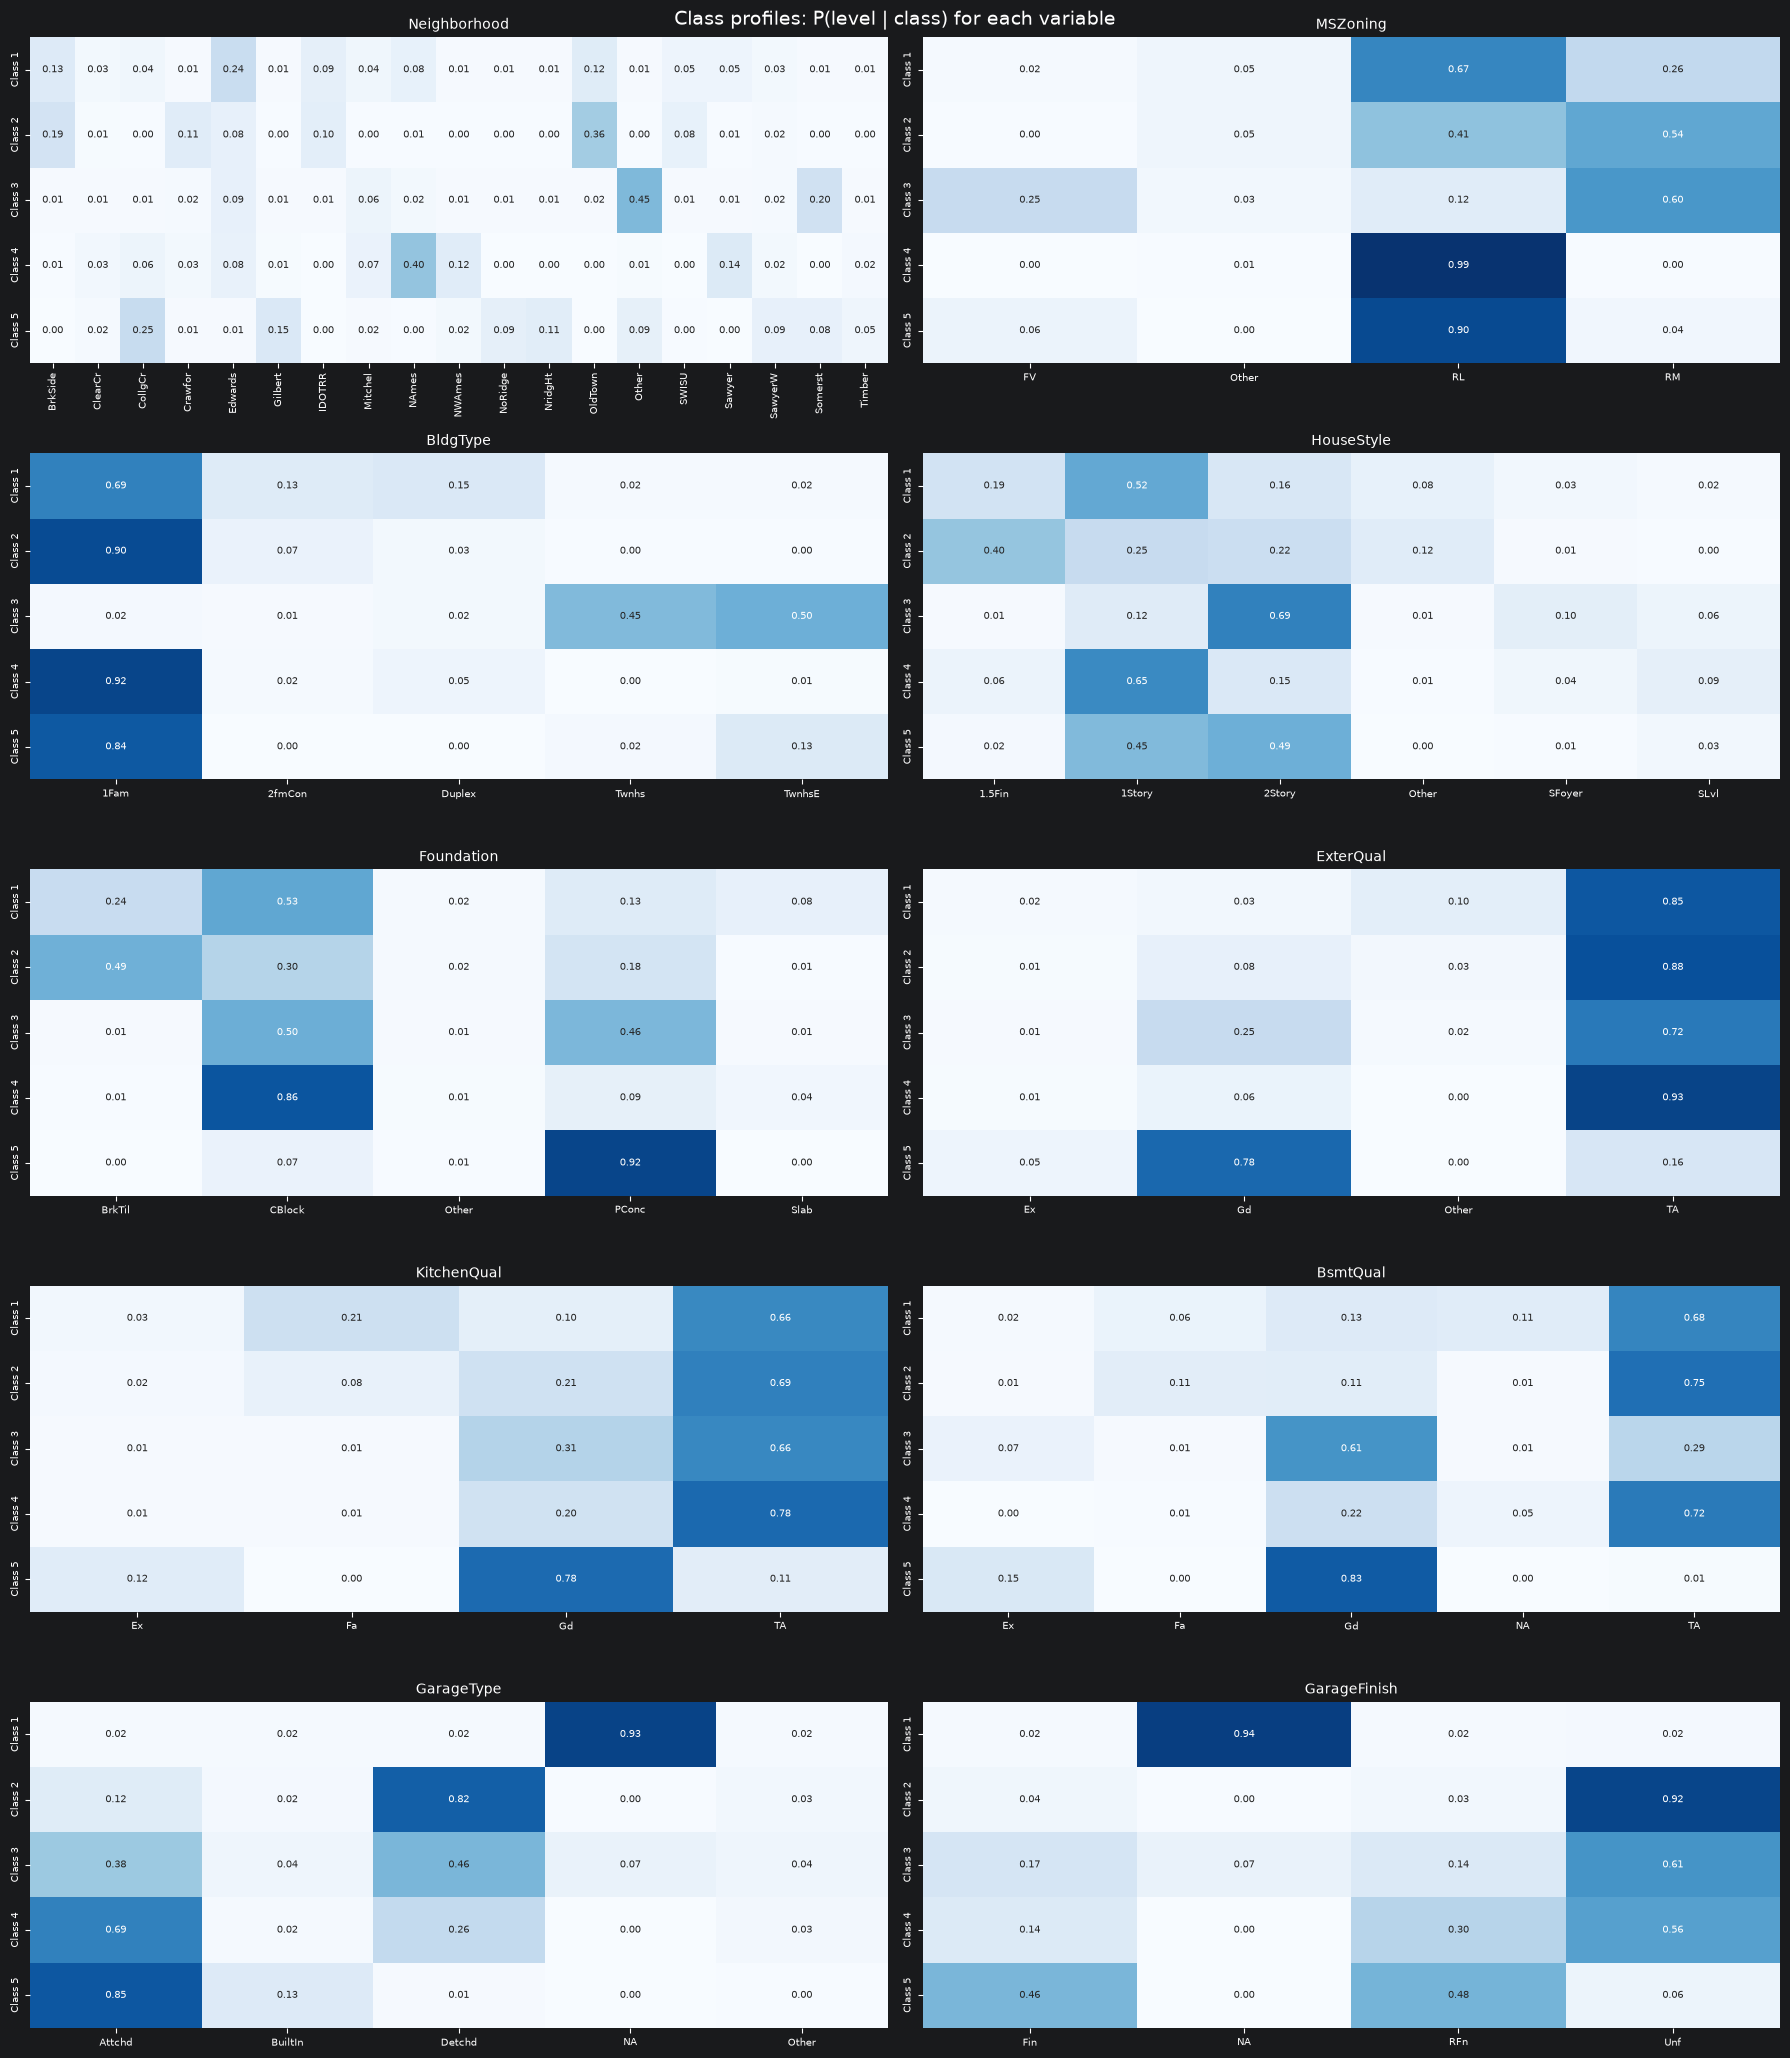

In [6]:
ncols = 2
nrows = int(np.ceil(len(LCA_COLS) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 2.2 + 0.45 * K * nrows + 1.5 * nrows))
for ax, c, th in zip(axes.flat, LCA_COLS, final["theta"]):
    prof = pd.DataFrame(th, index=[f"Class {k + 1}" for k in range(K)], columns=levels[c])
    sns.heatmap(prof, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                ax=ax, annot_kws={"fontsize": 7})
    ax.set_title(c, fontsize=10); ax.tick_params(labelsize=7)
for ax in axes.flat[len(LCA_COLS):]:
    ax.axis("off")
fig.suptitle("Class profiles: P(level | class) for each variable", fontsize=14)
plt.tight_layout(); plt.show()

In [7]:
## Price within each class

The classes were formed without using price. We now examine whether they differ in price level, in how price scales with living area, and in the spread and tail weight of the residuals.

SyntaxError: invalid syntax (1879111230.py, line 3)

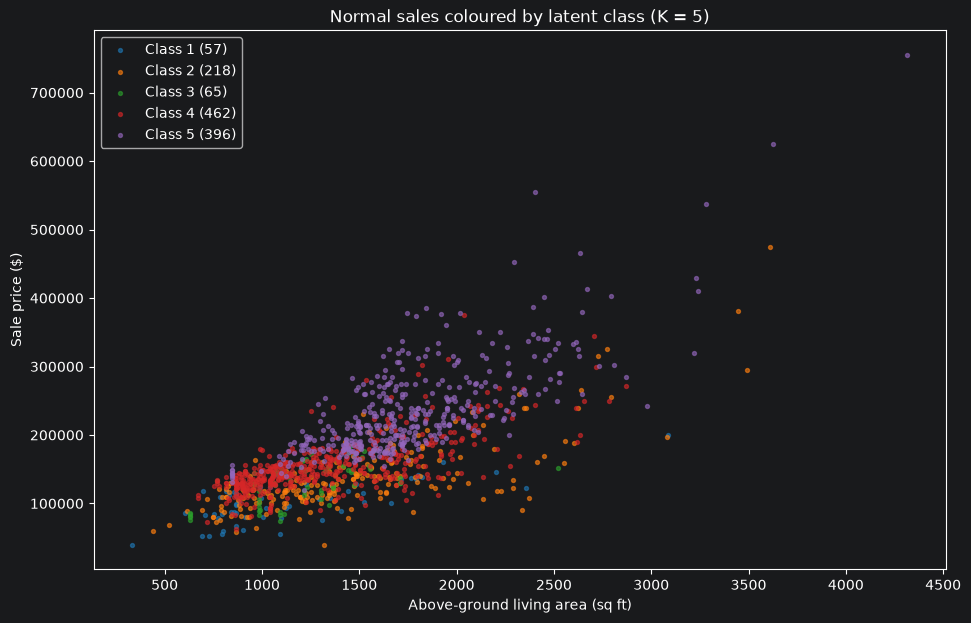

,Class,n,median_price,log_slope_per_100sqft,HC3_se,log_resid_sd,resid_kurtosis
0,1,57,103200.0,0.0426,0.0066,0.238,2.75
1,2,218,127250.0,0.0434,0.0033,0.222,5.80
2,3,65,133000.0,0.0484,0.0137,0.206,2.02
3,4,462,146900.0,0.0392,0.0020,0.169,4.84
4,5,396,217500.0,0.0443,0.0018,0.170,3.36


In [8]:
colours = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(11, 7))
rows = []
for k in range(1, K + 1):
    g = normal[normal["Class"] == k]
    ax.scatter(g["GrLivArea"], g["SalePrice"], s=8, alpha=0.6, color=colours[(k - 1) % 10],
               label=f"Class {k} ({len(g)})")
    fit = sm.OLS(np.log(g["SalePrice"]), sm.add_constant(g["GrLivArea"].astype(float))).fit(cov_type="HC3")
    rows.append({"Class": k, "n": len(g), "median_price": g["SalePrice"].median(),
                 "log_slope_per_100sqft": fit.params.iloc[1] * 100,
                 "HC3_se": fit.bse.iloc[1] * 100,
                 "log_resid_sd": fit.resid.std(ddof=2),
                 "resid_kurtosis": stats.kurtosis(fit.resid, fisher=False)})
ax.set_xlabel("Above-ground living area (sq ft)"); ax.set_ylabel("Sale price ($)")
ax.set_title(f"Normal sales coloured by latent class (K = {K})"); ax.legend()
plt.show()

display(pd.DataFrame(rows).round({"median_price": 0, "log_slope_per_100sqft": 4, "HC3_se": 4,
                                  "log_resid_sd": 3, "resid_kurtosis": 2}))